# 01 — Credit Application Data Exploration

This notebook establishes whether the Home Credit application table is suitable for a defensible
default-risk experiment. The focus is not decorative plotting: it is the modeling contract—one row
per applicant, a valid binary outcome, class imbalance, missingness mechanisms, anomalous values,
and plausible relationships between applicant characteristics and default.

**Questions answered**

1. Is the target and applicant key internally consistent?
2. How severe is class imbalance?
3. Which fields have material missingness, and could missingness itself carry information?
4. Are there documented sentinels or implausible values that require treatment?
5. Do selected numeric and categorical variables exhibit sensible risk separation?

This is exploratory evidence from a public competition dataset. It is not a population-validity or
regulatory assessment for a real lender.

## 1. Load data and establish the unit of observation

`SK_ID_CURR` is the application identifier and `TARGET = 1` is the adverse outcome supplied by the
competition. A duplicate ID would violate the one-applicant-per-row assumption and could leak the
same borrower across development partitions.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists()
)
DATA_PATH = ROOT / "data" / "raw" / "application_train.csv"
df = pd.read_csv(DATA_PATH)

integrity = pd.Series(
    {
        "rows": len(df),
        "columns": df.shape[1],
        "unique_applicants": df["SK_ID_CURR"].nunique(),
        "duplicate_applicant_ids": df["SK_ID_CURR"].duplicated().sum(),
        "missing_targets": df["TARGET"].isna().sum(),
        "default_rate": df["TARGET"].mean(),
    },
    name="value",
)
display(integrity.to_frame())

assert df["SK_ID_CURR"].is_unique
assert df["TARGET"].notna().all()
assert set(df["TARGET"].unique()) == {0, 1}

,value
rows,307511.000000
columns,122.000000
unique_applicants,307511.000000
duplicate_applicant_ids,0.000000
missing_targets,0.000000
default_rate,0.080729


## 2. Target imbalance

Defaults are the minority class. Accuracy would therefore be misleading: predicting every applicant
as non-default would appear strong while detecting no risk. Later notebooks use ROC-AUC, average
precision, KS, calibration, and business-policy metrics instead.

,applicants,share
TARGET,,
non_default,282686,91.93%
default,24825,8.07%


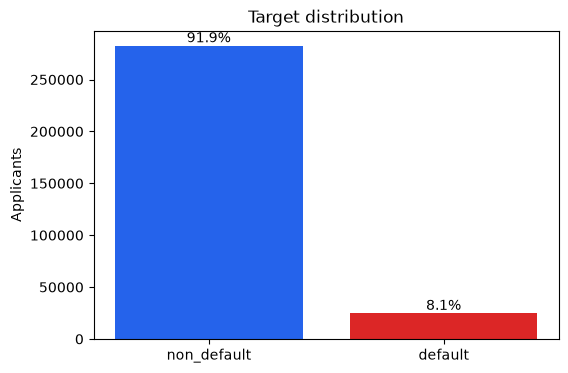

In [2]:
target_summary = df["TARGET"].value_counts().rename(index={0: "non_default", 1: "default"})
target_summary = target_summary.to_frame("applicants")
target_summary["share"] = target_summary["applicants"] / len(df)
display(target_summary.style.format({"share": "{:.2%}"}))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(target_summary.index, target_summary["applicants"], color=["#2563eb", "#dc2626"])
ax.set(title="Target distribution", ylabel="Applicants")
for index, row in target_summary.reset_index(drop=True).iterrows():
    ax.text(index, row["applicants"], f"{row['share']:.1%}", ha="center", va="bottom")
plt.show()

## 3. Missingness profile

Missing values should not be filled before splitting: doing so would let validation information
influence training medians and category modes. Some fields may also be missing structurally—for
example, a housing characteristic can be absent because it does not apply—so missingness can carry
signal and deserves domain review rather than automatic deletion.

,missing_percent
COMMONAREA_MEDI,69.9%
COMMONAREA_AVG,69.9%
COMMONAREA_MODE,69.9%
NONLIVINGAPARTMENTS_MODE,69.4%
NONLIVINGAPARTMENTS_AVG,69.4%
NONLIVINGAPARTMENTS_MEDI,69.4%
FONDKAPREMONT_MODE,68.4%
LIVINGAPARTMENTS_MODE,68.4%
LIVINGAPARTMENTS_AVG,68.4%
LIVINGAPARTMENTS_MEDI,68.4%


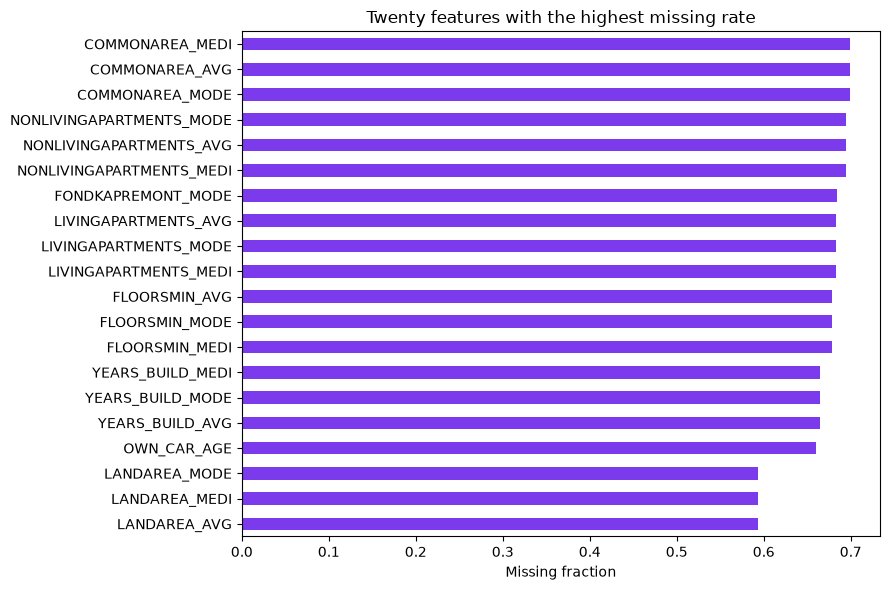

In [3]:
missing = df.isna().mean().sort_values(ascending=False)
missing_table = (missing.head(20) * 100).to_frame("missing_percent")
display(missing_table.style.format("{:.1f}%"))

fig, ax = plt.subplots(figsize=(9, 6))
missing.head(20).sort_values().plot(kind="barh", ax=ax, color="#7c3aed")
ax.set(title="Twenty features with the highest missing rate", xlabel="Missing fraction")
plt.tight_layout()
plt.show()

## 4. Data-quality and sentinel checks

Home Credit encodes `DAYS_EMPLOYED = 365243` for applicants without a conventional employment
history. Treating it as 1,000 years of employment would create an artificial extreme. The modeling
notebook converts this sentinel to missing and lets the training-only imputer handle it.

In [4]:
sentinel_count = int((df["DAYS_EMPLOYED"] == 365243).sum())
quality_checks = pd.Series(
    {
        "employment_sentinel_count": sentinel_count,
        "employment_sentinel_share": sentinel_count / len(df),
        "non_positive_income": int((df["AMT_INCOME_TOTAL"] <= 0).sum()),
        "non_positive_credit": int((df["AMT_CREDIT"] <= 0).sum()),
        "age_under_18": int(((-df["DAYS_BIRTH"] / 365.25) < 18).sum()),
    },
    name="value",
)
display(quality_checks.to_frame())

,value
employment_sentinel_count,55374.000000
employment_sentinel_share,0.180072
non_positive_income,0.000000
non_positive_credit,0.000000
age_under_18,0.000000


## 5. Numeric risk patterns

External scores should be inversely related to default risk, while larger payment burdens may raise
risk. These are associations—not causal effects—and univariate plots do not control for applicant
mix or correlated variables.

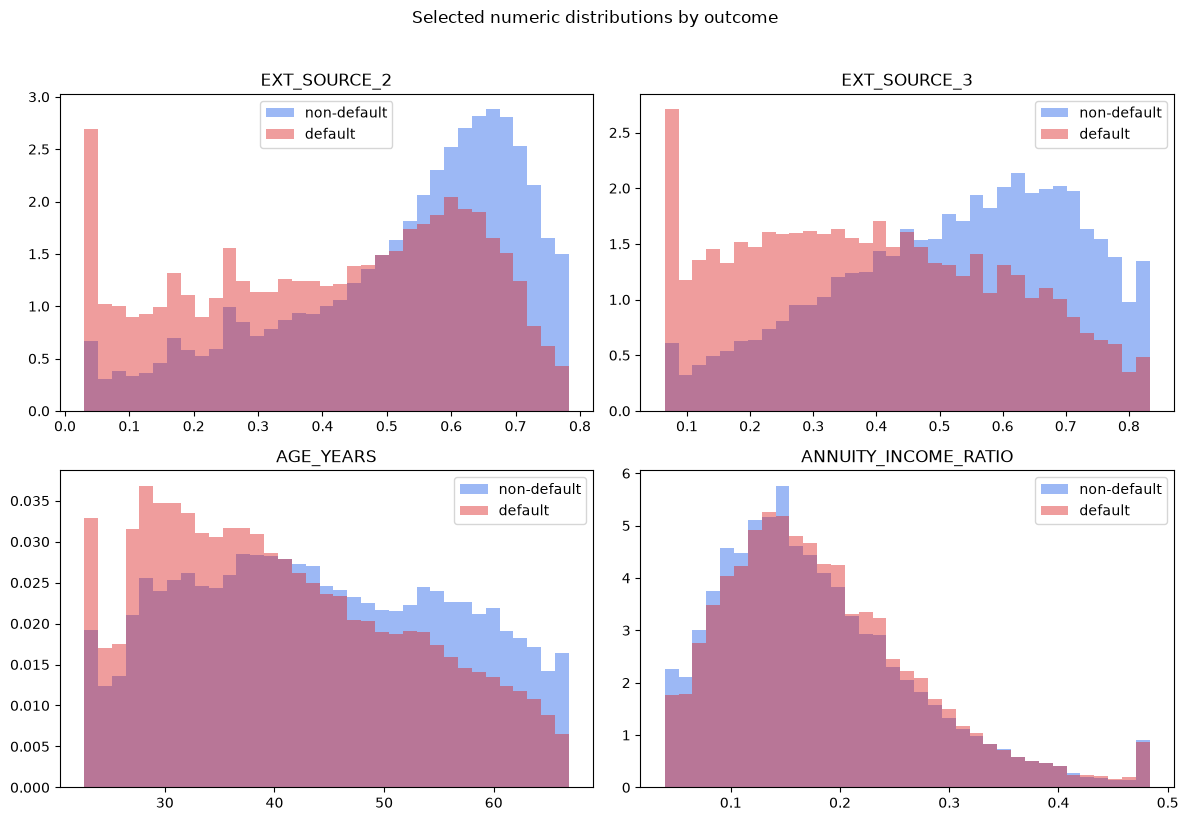

In [5]:
numeric_view = pd.DataFrame(
    {
        "TARGET": df["TARGET"],
        "EXT_SOURCE_2": df["EXT_SOURCE_2"],
        "EXT_SOURCE_3": df["EXT_SOURCE_3"],
        "AGE_YEARS": -df["DAYS_BIRTH"] / 365.25,
        "ANNUITY_INCOME_RATIO": (
            df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"].replace(0, np.nan)
        ),
    }
)
plot_features = ["EXT_SOURCE_2", "EXT_SOURCE_3", "AGE_YEARS", "ANNUITY_INCOME_RATIO"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, ax in zip(plot_features, axes.flat):
    clipped = numeric_view[feature].clip(
        numeric_view[feature].quantile(0.01), numeric_view[feature].quantile(0.99)
    )
    for target, label, color in [(0, "non-default", "#2563eb"), (1, "default", "#dc2626")]:
        ax.hist(
            clipped[numeric_view["TARGET"] == target].dropna(),
            bins=35,
            density=True,
            alpha=0.45,
            label=label,
            color=color,
        )
    ax.set_title(feature)
    ax.legend()
plt.suptitle("Selected numeric distributions by outcome", y=1.02)
plt.tight_layout()
plt.show()

## 6. Categorical segments

Segment tables include both default rate and exposure count. A high rate in a tiny category should
not be treated as reliable evidence, and categories can proxy for socioeconomic characteristics.

In [6]:
def segment_table(column: str) -> pd.DataFrame:
    return (
        df.assign(**{column: df[column].fillna("Missing")})
        .groupby(column)["TARGET"]
        .agg(applicants="size", defaults="sum", default_rate="mean")
        .sort_values("default_rate", ascending=False)
    )


income_segments = segment_table("NAME_INCOME_TYPE")
education_segments = segment_table("NAME_EDUCATION_TYPE")
display(income_segments.style.format({"default_rate": "{:.2%}"}))
display(education_segments.style.format({"default_rate": "{:.2%}"}))

,applicants,defaults,default_rate
NAME_INCOME_TYPE,,,
Maternity leave,5,2,40.00%
Unemployed,22,8,36.36%
Working,158774,15224,9.59%
Commercial associate,71617,5360,7.48%
State servant,21703,1249,5.75%
Pensioner,55362,2982,5.39%
Businessman,10,0,0.00%
Student,18,0,0.00%


,applicants,defaults,default_rate
NAME_EDUCATION_TYPE,,,
Lower secondary,3816,417,10.93%
Secondary / secondary special,218391,19524,8.94%
Incomplete higher,10277,872,8.48%
Higher education,74863,4009,5.36%
Academic degree,164,3,1.83%


## 7. Modeling implications

- The dataset contains 307,511 unique applicants and an approximately 8% default rate.
- Class imbalance requires ranking, minority-class, calibration, and decision metrics—not accuracy.
- Missingness is material and must be learned/handled inside the training pipeline.
- `DAYS_EMPLOYED = 365243` is a documented sentinel, not a genuine duration.
- External scores, age, payment burden, income type, and education show plausible risk separation.
- These relationships may encode historical and socioeconomic bias; fairness is audited later.
- The available split is stratified random, not out-of-time. Claims about temporal stability would
  require application dates or a genuinely later portfolio.

**Next:** Notebook 02 freezes applicant-level splits and builds an interpretable Logistic Regression
baseline without allowing preprocessing information to cross from validation or test into training.